## Системы искусственного интеллекта

## ЛР4. Decision Tree
[10 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
%load_ext cuml.accel

Tesla T4, 15360 MiB


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 179562398

In [3]:
import glob
import kagglehub

In [4]:
%pip install kagglehub

## Этапы

Задание состоит в детальном изучении данных и построении модели предсказания стоимости объекта недвижимости.

Что входит в работу:

*  Загрузка и предобработка данных.
*  Применение и настройка линейных моделей.
*  Применение и настройка решающего дерева.
*  Сравнение моделей.
*  Оценка важности признаков.


-------------

## Задание

Мы будем работать с данными из [датасета](https://www.kaggle.com/datasets/mrdaniilak/russia-real-estate-20182021), в котором содержится информация об объектах недвижимости в России с их стоимостью за 2018-2021 гг.

*   Цена — Цена в рублях РФ (*числовое*)
*   Дата — дата публикации объявления (*временное*)
*   Время — время публикаци объявления (*временное*)
*   Коорданата x — значение координаты (широта) (*числовое*)
*   Коорданата y — значение координаты (долгота) (*числовое*)
*   Номер — код региона РФ (*категориальное*)
*   Тип здания — тип сооружения, в котором находится квартира (*категориальное*)
*   Этаж — номер этажа, на котором находится квартира (*категориальное* или *числовое*?)
*   Число этажей в доме — общее количество этажей в здании (*категориальное* или *числовое*?)
*   Комнаты — количество комнат в квартире, -1 означает студии с открытой планировкой (*категориальное* или *числовое*?)
*   Площадь — общая площадь квартиры в кв. метрах (*числовое*)
*   Площадь кухни — площадь кухни в кв. метрах (*числовое*)
*   Тип квартиры — тип квартиры, где 1 означает вторичный рынок недвижимости, 11 - новостройка (*категориальное*)

<font color='CornflowerBlue'>**Целевой переменной (target, y)**</font> будем считать цену (столбец `price`)

### **0. Загружаем данные**

In [5]:
import pandas as pd

In [6]:
path = kagglehub.dataset_download("mrdaniilak/russia-real-estate-20182021")
files = glob.glob(path + "/**/*.csv", recursive=True)
df = pd.read_csv(files[0])
print(df.columns)

Using Colab cache for faster access to the 'russia-real-estate-20182021' dataset.
Index(['price', 'date', 'time', 'geo_lat', 'geo_lon', 'region',
       'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area',
       'object_type'],
      dtype='object')


In [7]:
df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
0,6050000,2018-02-19,20:00:21,59.805808,30.376141,2661,1,8,10,3,82.6,10.8,1
1,8650000,2018-02-27,12:04:54,55.683807,37.297405,81,3,5,24,2,69.1,12.0,1
2,4000000,2018-02-28,15:44:00,56.295250,44.061637,2871,1,5,9,3,66.0,10.0,1
3,1850000,2018-03-01,11:24:52,44.996132,39.074783,2843,4,12,16,2,38.0,5.0,11
4,5450000,2018-03-01,17:42:43,55.918767,37.984642,81,3,13,14,2,60.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5477001,19739760,2021-05-01,20:13:58,55.804736,37.750898,3,1,8,17,4,93.2,13.8,11
5477002,12503160,2021-05-01,20:14:01,55.841415,37.489624,3,2,17,32,2,45.9,6.6,11
5477003,8800000,2021-05-01,20:14:04,56.283909,44.075408,2871,2,4,17,3,86.5,11.8,1
5477004,11831910,2021-05-01,20:14:12,55.804736,37.750898,3,1,8,33,2,52.1,18.9,11


In [8]:
region_name = {
    '2661': 'Санкт-Петербург',
    '3446': 'Ленинградская область',
    '3': 'Москва',
    '81': 'Московская область',
    '2843': 'Краснодарский край',
    '2871': 'Нижегородская область',
    '3230': 'Ростовская область',
    '3106': 'Самарская область',
    '2922': 'Республика Татарстан',
    '2900': 'Ставропольский край',
    '2722': 'Республика Башкортостан',
    '6171': 'Свердловская область',
    '4417': 'Республика Коми',
    '5282': 'Челябинская область',
    '5368': 'Иркутская область',
    '5520': 'Пермский край',
    '6817': 'Алтайский край',
    '9579': 'Республика Бурятия',
    '2604': 'Ярославская область',
    '1010': 'Удмуртская Республика',
    '7793': 'Псковская область',
    '13919': 'Республика Северная Осетия — Алания',
    '2860': 'Кемеровская область',
    '3019': 'Чувашская Республика',
    '4982': 'Республика Марий Эл',
    '9648': 'Кабардино-Балкарская Республика',
    '5241': 'Республика Мордовия',
    '3870': 'Красноярский край',
    '3991': 'Тюменская область',
    '2359': 'Республика Хакасия',
    '9654': 'Новосибирская область',
    '2072': 'Воронежская область',
    '8090': 'Республика Карелия',
    '4007': 'Республика Дагестан',
    '11171': 'Республика Саха (Якутия)',
    '10160': 'Забайкальский край',
    '7873, 6937': 'Республика Крым',
    '2594': 'Кировская область',
    '8509': 'Республика Калмыкия',
    '11416': 'Республика Адыгея',
    '11991': 'Карачаево-Черкесская Республика',
    '5178': 'Республика Тыва',
    '13913': 'Республика Ингушетия',
    '6309': 'Республика Алтай',
    '5952': 'Белгородская область',
    '6543': 'Архангельская область',
    '2880': 'Тверская область',
    '5993': 'Пензенская область',
    '2484': 'Ханты-Мансийский автономный округ',
    '4240': 'Липецкая область',
    '5789': 'Владимирская область',
    '14880': 'Ямало-Ненецкий автономный округ',
    '1491': 'Рязанская область',
    '2885': 'Чеченская Республика',
    '5794': 'Смоленская область',
    '2528': 'Саратовская область',
    '4374': 'Вологодская область',
    '4695': 'Волгоградская область',
    '2328': 'Калужская область',
    '5143': 'Тульская область',
    '2806': 'Тамбовская область',
    '14368': 'Мурманская область',
    '5736': 'Новгородская область',
    '7121': 'Курская область',
    '4086': 'Хабаровский край',
    '821': 'Брянская область',
    '10582': 'Астраханская область',
    '7896': 'Калининградская область',
    '8640': 'Омская область',
    '5703': 'Курганская область',
    '10201': 'Томская область',
    '4249': 'Ульяновская область',
    '3153': 'Оренбургская область',
    '4189': 'Костромская область',
    '2814': 'Орловская область',
    '13098': 'Камчатский край',
    '8894': 'Ивановская область',
    '7929': 'Амурская область',
    '16705': 'Магаданская область',
    '69': 'Еврейская автономная область',
    '4963': 'Приморский край',
    '1901': 'Сахалинская область',
    '61888': 'Ненецкий автономный округ'
}

### **<font color='DarkOrange'> Задача 1. [1 балл]</font>**


In [9]:
TARGET = 'price'

# Create a new mapping handling keys that represent multiple region IDs separated by commas
new_region_name = {}
for k, v in region_name.items():
    if ',' in k:
        for sub_key in k.split(','):
            new_region_name[int(sub_key.strip())] = v
    else:
        new_region_name[int(k)] = v

region_name = new_region_name

reg_names = df.groupby('region')[TARGET].count().reset_index(name='target_count')

reg_names['region_name'] = reg_names['region'].map(region_name)

reg_names.nlargest(10, 'target_count')

,region,target_count,region_name
70,9654,1049435,Новосибирская область
18,2843,637224,Краснодарский край
2,81,500368,Московская область
14,2661,461820,Санкт-Петербург
0,3,439511,Москва
54,6171,237289,Свердловская область
24,2922,230545,Республика Татарстан
28,3230,222652,Ростовская область
45,5282,155645,Челябинская область
31,3991,141633,Тюменская область


В качестве региона для построения модели была выбрана **Челябинская область**

In [10]:
SEL_REGION = 5282
df = df[df['region'] == SEL_REGION]

df = df.dropna(subset=[TARGET])

df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
37,3160000,2018-04-11,15:58:47,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11
124,2050000,2018-07-26,07:38:12,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1
278,2050000,2018-09-08,00:29:10,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1
1491,1900000,2018-09-08,03:59:06,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11
1545,1950000,2018-09-08,05:50:03,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5476777,2270000,2021-05-01,19:32:40,55.246425,61.370958,5282,4,3,5,4,74.4,8.6,1
5476851,2400000,2021-05-01,19:46:25,55.128211,61.420405,5282,4,4,5,3,60.0,6.0,1
5476861,1750000,2021-05-01,19:46:47,55.247058,61.371008,5282,3,2,3,2,46.7,10.0,1
5476862,3500000,2021-05-01,19:46:52,55.166973,61.290378,5282,1,9,10,2,61.0,8.0,1


Удаление некорректных записей

In [11]:
df = df.drop_duplicates()

remove_cond = (
    (df['price'] <= 0) |
    (df['area'] <= 0) |
    (df['kitchen_area'] <= 0) |
    (df['kitchen_area'] >= df['area']) |
    (df['rooms'] < -1) | (df['rooms'] == 0) |
    (df['kitchen_area'] < 1) |
    (df['geo_lat'] == 0) | (df['geo_lon'] == 0) |
    (df['level'] < 1) |
    (df['levels'] < 1) |
    (df['level'] > df['levels'])
)

df = df[~remove_cond]
df

,price,date,time,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type
37,3160000,2018-04-11,15:58:47,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11
124,2050000,2018-07-26,07:38:12,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1
278,2050000,2018-09-08,00:29:10,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1
1491,1900000,2018-09-08,03:59:06,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11
1545,1950000,2018-09-08,05:50:03,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5476777,2270000,2021-05-01,19:32:40,55.246425,61.370958,5282,4,3,5,4,74.4,8.6,1
5476851,2400000,2021-05-01,19:46:25,55.128211,61.420405,5282,4,4,5,3,60.0,6.0,1
5476861,1750000,2021-05-01,19:46:47,55.247058,61.371008,5282,3,2,3,2,46.7,10.0,1
5476862,3500000,2021-05-01,19:46:52,55.166973,61.290378,5282,1,9,10,2,61.0,8.0,1


Проверка на выбросы по признакам

In [12]:
display(
    df[['price', 'area', 'kitchen_area', 'level', 'levels', 'rooms', 'geo_lat', 'geo_lon', 'date', 'time']]
    .describe()
    .T[['min', '25%', '50%', '75%', 'max']]
    .round(2)
)

,min,25%,50%,75%,max
price,150.00,1355000.00,1780000.00,2350000.00,1.100000e+09
area,2.34,39.30,48.00,63.00,1.260000e+03
kitchen_area,1.00,7.00,9.00,10.60,2.100000e+02
level,1.00,2.00,4.00,7.00,2.600000e+01
levels,1.00,5.00,9.00,10.00,3.700000e+01
rooms,-1.00,1.00,2.00,2.00,9.000000e+00
geo_lat,52.39,55.13,55.17,55.19,5.629000e+01
geo_lon,57.15,61.29,61.36,61.42,6.299000e+01


Удаление выбросов по показателю цены на единицу площади

In [13]:

price_sqm = df['price'] / df['area']
lo_sqm, hi_sqm = price_sqm.quantile([0.005, 0.995])
df = df[price_sqm.between(lo_sqm, hi_sqm)]

display(
    df[['price', 'area', 'kitchen_area', 'level', 'levels', 'rooms', 'geo_lat', 'geo_lon', 'date', 'time']]
    .describe()
    .T[['min', '25%', '50%', '75%', 'max']]
    .round(2)
)

,min,25%,50%,75%,max
price,175000.00,1360000.00,1780000.00,2350000.00,28500000.00
area,10.00,39.10,48.00,63.00,500.00
kitchen_area,1.00,7.00,9.00,10.50,130.00
level,1.00,2.00,4.00,7.00,26.00
levels,1.00,5.00,9.00,10.00,37.00
rooms,-1.00,1.00,2.00,2.00,9.00
geo_lat,52.39,55.13,55.17,55.19,56.29
geo_lon,57.15,61.29,61.37,61.42,62.98


Явных выбросов в выборке не наблюдается с поправкой на то, что rooms=-1 представляется как квартира-студия

Создание колонки с годом и удаление date и time

In [14]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year

df = df.drop(columns=['date', 'time'])

/tmp/ipykernel_7027/2274961657.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = pd.to_datetime(df['date'])
/tmp/ipykernel_7027/2274961657.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['year'] = df['date'].dt.year


Исключение 1% с каждого хвоста распределения по целевой переменной и по признакам с высокой скошенностью

In [15]:
def rem_q(d, col, q=0.01):
    lo, hi = d[col].quantile([q, 1 - q])
    return d[d[col].between(lo, hi)]

for col in ['price', 'area', 'kitchen_area']:
    df = rem_q(df, col)

Исследование гистограмм и скошенности признаков

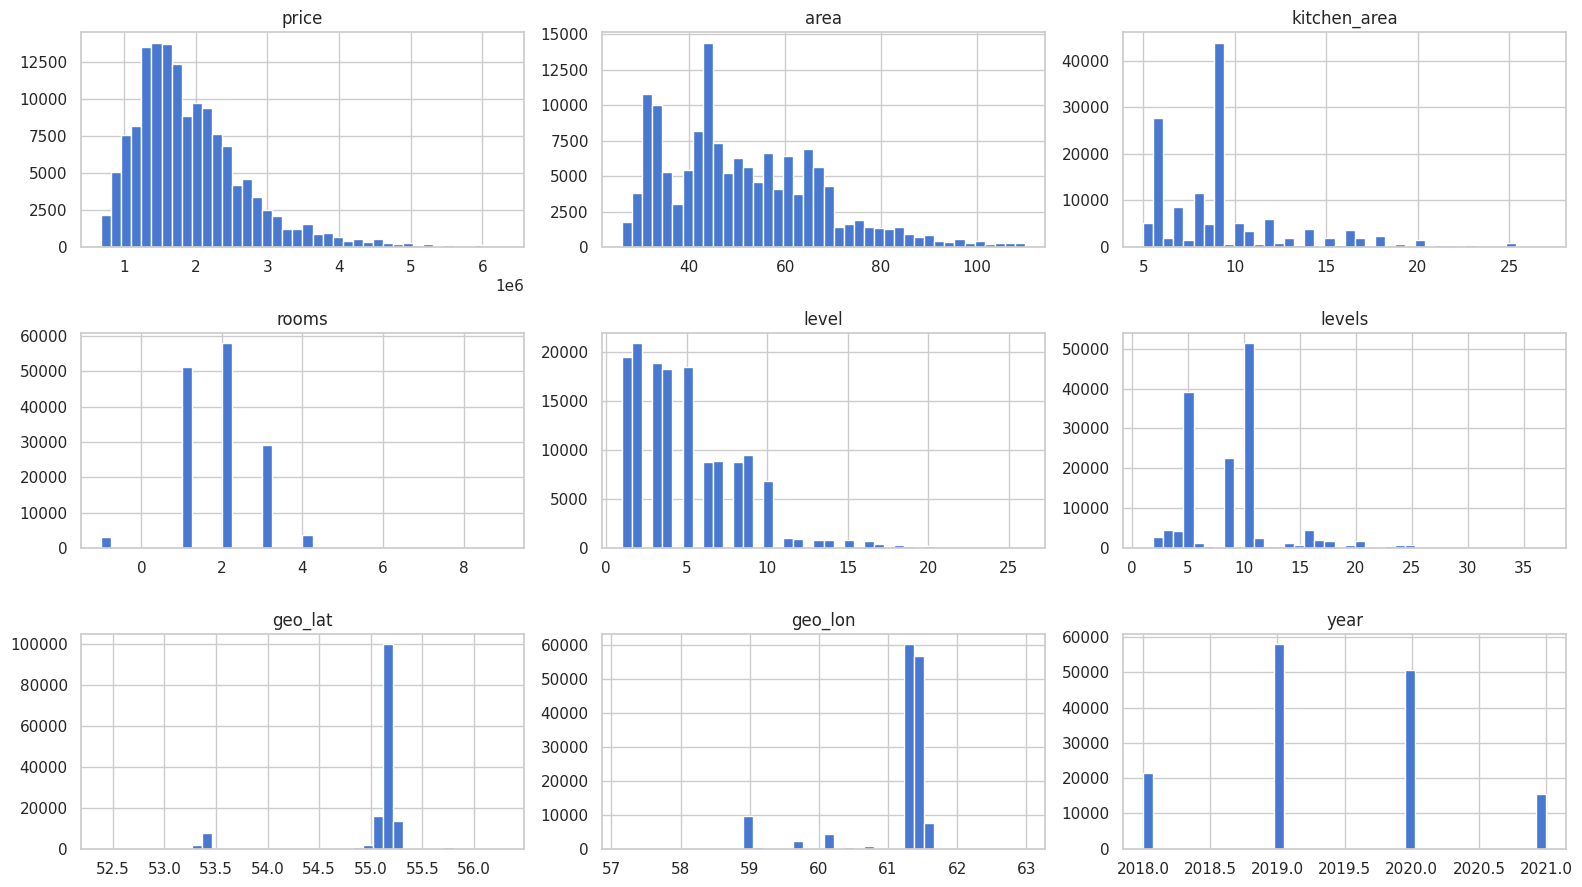

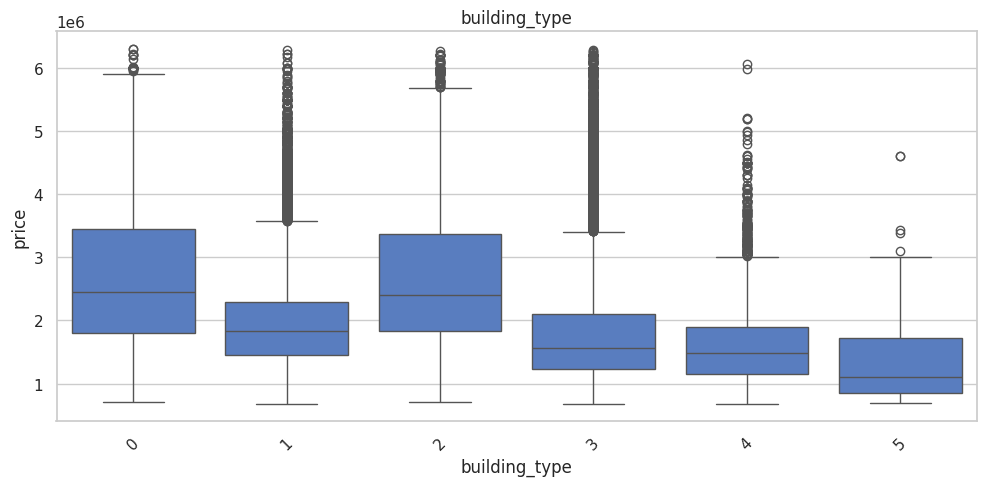

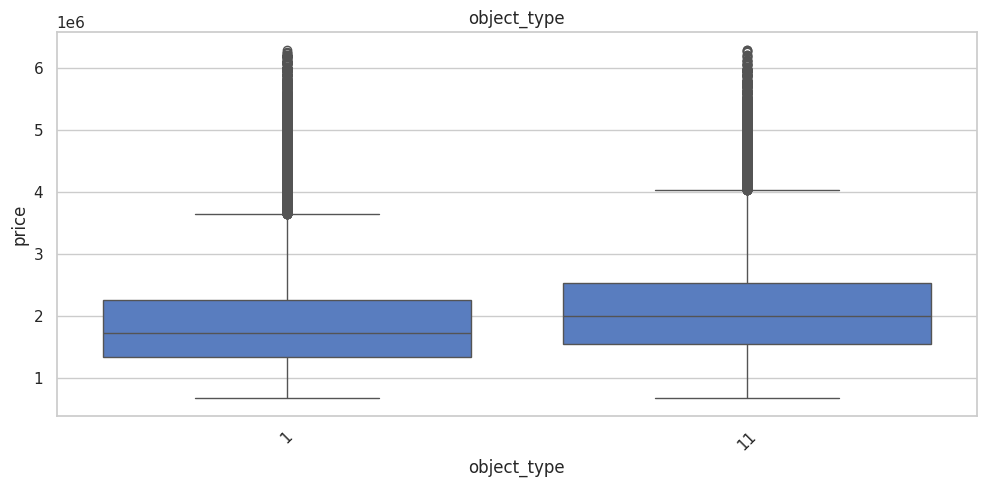

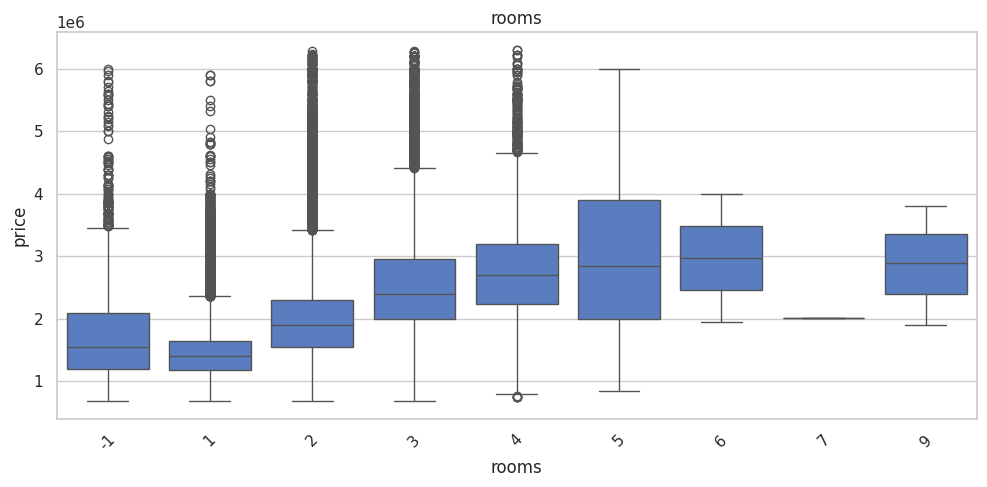

price           1.46
area            0.83
kitchen_area    1.69
rooms          -0.13
level           1.30
levels          1.21
geo_lat        -3.09
geo_lon        -2.50
year            0.08
dtype: float64


In [16]:
from matplotlib import pyplot as plt


num_features = ['price', 'area', 'kitchen_area', 'rooms', 'level', 'levels', 'geo_lat', 'geo_lon', 'year']
discr_feats = ['building_type', 'object_type', 'rooms']

df[num_features].hist(bins=40, figsize=(16, 9))
plt.tight_layout()
plt.show()


for cf in discr_feats:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x=cf, y='price')
    plt.title(f'{cf}')
    plt.xlabel(cf)
    plt.ylabel('price')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

print(df[num_features].skew().round(2))


Несмотря на то, что room является дискретным признаком, его можно определить в числовые, потому что он упорядочен и имеет корреляцию с таргетом

У признаков price и kitchen_area явно выражается сильная скошенность вправо. Эти признаки не являются категориальными, следовательно, можно попробовать их устранить нелинейным преобразованием, к примеру, логарифмированием

In [17]:
import numpy as np


for c in ['price', 'area', 'kitchen_area']:
    df['log_' + c] = np.log1p(df[c])
df['obj_type_11'] = (df['object_type'] == 11).astype(int)

print(df[['price', 'log_price', 'area', 'log_area', 'kitchen_area', 'log_kitchen_area']].skew().round(2))
df.head()

price               1.46
log_price           0.22
area                0.83
log_area            0.18
kitchen_area        1.69
log_kitchen_area    0.81
dtype: float64


,price,geo_lat,geo_lon,region,building_type,level,levels,rooms,area,kitchen_area,object_type,year,log_price,log_area,log_kitchen_area,obj_type_11
37,3160000,55.172116,61.279772,5282,3,13,16,2,56.0,11.0,11,2018,14.966083,4.043051,2.484907,1
124,2050000,55.107360,61.616595,5282,3,6,9,3,61.0,9.0,1,2018,14.533351,4.127134,2.302585,0
278,2050000,55.166017,61.292384,5282,1,1,10,2,65.0,14.0,1,2018,14.533351,4.189655,2.708050,0
1491,1900000,55.158606,61.446504,5282,1,7,10,1,43.0,9.0,11,2018,14.457365,3.784190,2.302585,1
1545,1950000,55.123232,61.604227,5282,1,5,5,3,70.0,10.0,1,2018,14.483340,4.262680,2.397895,0


Сравнение гистограмм после устранения скошенности

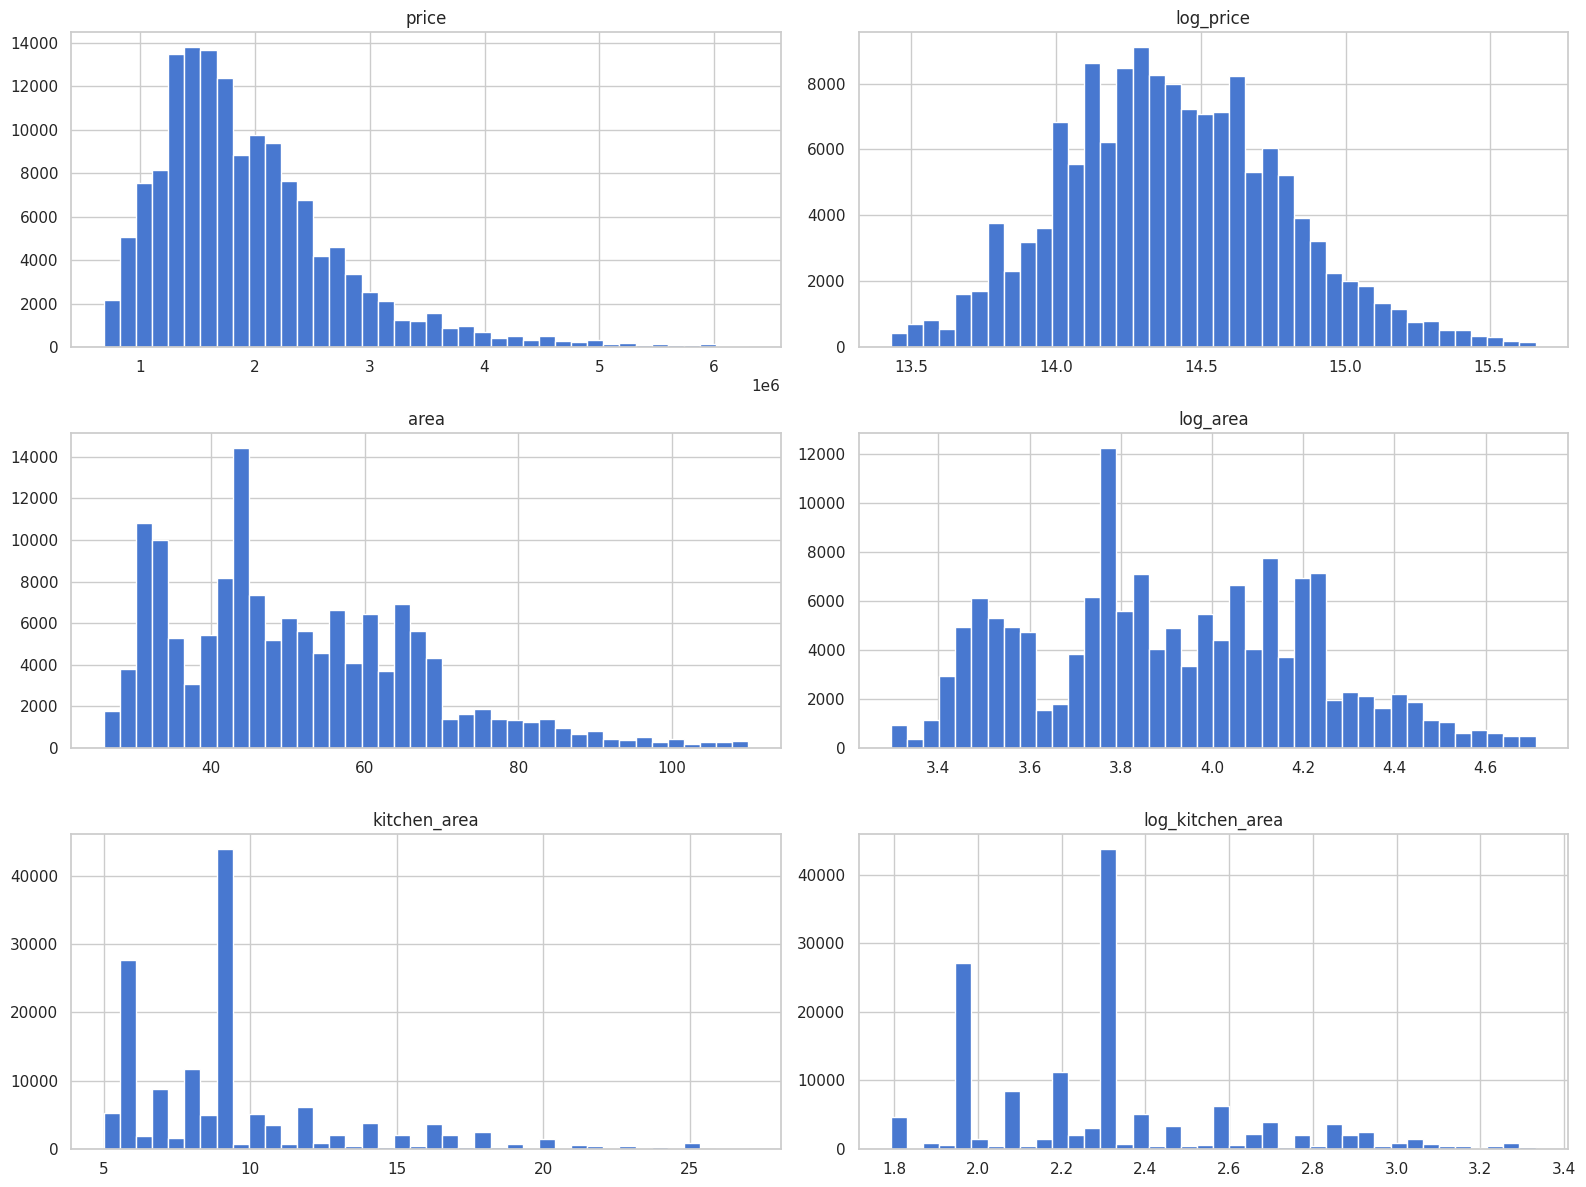

In [18]:
from matplotlib import pyplot as plt


f = ['price', 'log_price', 'area', 'log_area', 'kitchen_area', 'log_kitchen_area']

df[f].hist(bins=40, figsize=(16, 12))

plt.tight_layout()
plt.show()

Проверка на нормальность распределения таргета

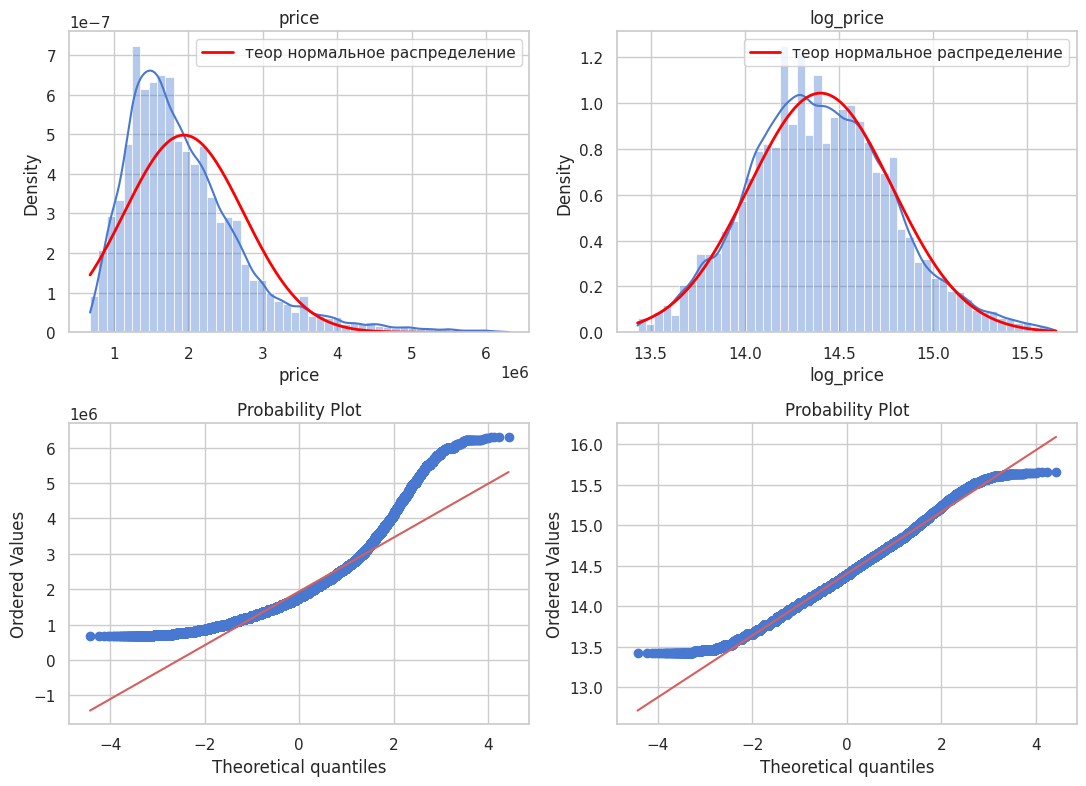

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 145273.
  res = hypotest_fun_out(*samples, **kwds)


,column,normaltest_pvalue,shapiro_pvalue
0,price,0.0,0.0
1,log_price,0.0,0.0


In [19]:
from scipy import stats

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for i, c in enumerate(['price', 'log_price']):
    data = df[c].dropna()

    sns.histplot(data, bins=50, stat='density',
                 kde=True, ax=ax[0, i], alpha=0.4)

    x = np.linspace(data.min(), data.max(), 1000)
    y = stats.norm.pdf(x, data.mean(), data.std())

    ax[0, i].plot(x, y, color='red', lw=2,
                  label='теор нормальное распределение')
    ax[0, i].set_title(c)
    ax[0, i].legend()


    stats.probplot(df[c], dist='norm', plot=ax[1, i])
plt.tight_layout()
plt.show()


normality = pd.DataFrame([
    {
        'column': c,
        'normaltest_pvalue': stats.normaltest(df[c].dropna()).pvalue.round(5),
        'shapiro_pvalue': stats.shapiro(df[c].dropna()).pvalue.round(5)
    } for c in ['price', 'log_price']
])
display(normality)

Из графиков видно, что распределение логарифмированного таргета достаточно близко к нормальному, несмотря на то, что по критериям нормальности p-value стремится к нулю из-за большого размера выборки
Исходное распределение нормальным не является в силу правосторонней асимметрии

Проверка признаков на мультиколлинеарность

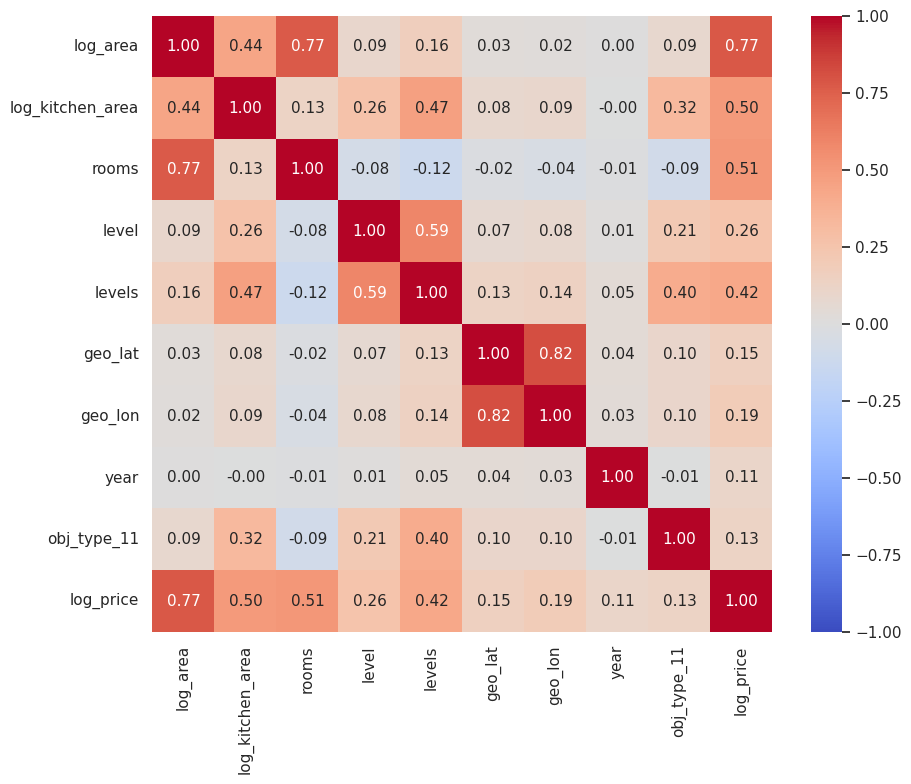

,feature,VIF
0,log_area,3.65
1,rooms,3.12
2,geo_lon,3.00
3,geo_lat,2.99
4,levels,2.08
5,log_kitchen_area,1.69
6,level,1.54
7,obj_type_11,1.24
8,year,1.01


In [20]:
from sklearn.linear_model import LinearRegression

features = ['log_area', 'log_kitchen_area', 'rooms', 'level', 'levels',
            'geo_lat', 'geo_lon', 'year', 'obj_type_11', 'building_type']

cat_features = ['building_type']
num_features = [f for f in features if f not in cat_features]

corr = df[num_features + ['log_price']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)
plt.show()
vif = {}
for f in num_features:
    rest = df[num_features].drop(columns=f)
    vif[f] = 1 / (1 - LinearRegression().fit(rest, df[f]).score(rest, df[f]))

vif_df = (
    pd.DataFrame({
        'feature': list(vif.keys()),
        'VIF': list(vif.values())
    })
    .sort_values('VIF', ascending=False)
    .round(2)
    .reset_index(drop=True)
)
vif_df

Значения в матрице корреляции признаков не превышают 0.81, а значения VIF по признаков < 5, следовательно, нет оснований исключать признаки на основе мультиколлинеарности

### **<font color='DarkOrange'> Задача 2. [1 балл]</font>**

Подготовка к обучению



In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.svm import LinearSVR

SEED=179562398
LOG_TARGET = True

X = df[features]
y = df['log_price'] if LOG_TARGET else df['price']

Разбиение на трейн и тест

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED
)

In [23]:
from sklearn.metrics import mean_squared_error


def to_orig(y):
    return np.expm1(y) if LOG_TARGET else y

def rmse_orig(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(to_orig(y_true), to_orig(y_pred))))

def rmse_target(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

Пайплайн для моделей

Для численных признаков используем StandardScaler, для building_type OneHotEncoder

In [24]:
def make_pipeline(model):
    transformer = ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features),
    ]).set_output(transform='pandas')
    return Pipeline([
        ('transformer', transformer),
        ('model', model),
    ])

### **<font color='DarkOrange'> Задача 3. [1 балл]</font>**


Обучение моделей

In [25]:
dummy = make_pipeline(DummyRegressor()).fit(X_train, y_train)

In [26]:
ridge = make_pipeline(Ridge()).fit(X_train, y_train)

In [27]:
svr = make_pipeline(SVR(kernel='linear', cache_size=1000)).fit(X_train, y_train)

Инференс и сравнение метрик по RMSE

In [28]:
pred_dummy = dummy.predict(X_test)
pred_ridge = ridge.predict(X_test)
pred_svr = svr.predict(X_test)

res = pd.DataFrame(
    {
        'RMSE': [
            rmse_orig(y_test, pred_dummy),
            rmse_orig(y_test, pred_ridge),
            rmse_orig(y_test, pred_svr),
        ],
        'RMSE (log)': [
            rmse_target(y_test, pred_dummy),
            rmse_target(y_test, pred_ridge),
            rmse_target(y_test, pred_svr),
        ],
    },
    index=['Dummy', 'Ridge', 'SVR'],
).round(3)
res

,RMSE,RMSE (log)
Dummy,814225.629,0.382
Ridge,420959.861,0.201
SVR,420648.057,0.201


### **<font color='DarkOrange'> Задача 4. [2 баллa]</font>**

Обучите [решающее дерево](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor) с параметрами по умолчанию на тренировочных данных, сделайте предсказание на тесте и вычислите на тесте RMSE

In [29]:
tree_base = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_base.fit(X_train, y_train)

y_pred_tree_base = tree_base.predict(X_test)

tree_base_rmse = rmse_target(y_test, y_pred_tree_base)
tree_base_rmse_rub = rmse_orig(y_test, y_pred_tree_base)
tree_base_r2 = r2_score(y_test, y_pred_tree_base)

print(f"RMSE на тесте (log-шкала):   {tree_base_rmse:.5f}")
print(f"RMSE на тесте (в рублях РФ): {tree_base_rmse_rub:,.2f} руб.")
print(f"R^2 на тесте:                {tree_base_r2:.5f}")

RMSE на тесте (log-шкала):   0.15778
RMSE на тесте (в рублях РФ): 320,449.57 руб.
R^2 на тесте:                0.82897


Нужно ли масшабировать признаки для обучения решающего дерева? Проверьте это, заново разбив данные на тренировочную и тестовую части (назовите новые полученные объекты новыми названиями), и проведите обучение, предсказание и оценку метрики до масштабирования и после.

<font color='LightSteelBlue'>**Подсказка:**</font> Можно использовать любой метод мастшабирования признаков

In [30]:
X_train_check, X_test_check, y_train_check, y_test_check = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

#### без масштабирования

In [31]:
tree_unscaled = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_unscaled.fit(X_train_check, y_train_check)
pred_unscaled = tree_unscaled.predict(X_test_check)
rmse_unscaled = root_mean_squared_error(y_test_check, pred_unscaled)

#### с масштабированием

In [32]:
check_scaler = StandardScaler()
X_train_check_scaled = pd.DataFrame(
    check_scaler.fit_transform(X_train_check),
    columns=X.columns,
    index=X_train_check.index
)
X_test_check_scaled = pd.DataFrame(
    check_scaler.transform(X_test_check),
    columns=X.columns,
    index=X_test_check.index
)

tree_scaled = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_scaled.fit(X_train_check_scaled, y_train_check)
pred_scaled = tree_scaled.predict(X_test_check_scaled)
rmse_scaled = root_mean_squared_error(y_test_check, pred_scaled)

#### Сравнение

In [33]:
rmse_diff = abs(rmse_unscaled - rmse_scaled)

scaling_results_df = pd.DataFrame({
    'метрика': [
        'RMSE на тесте (log-шкала)',
        'R^2 на тесте',
        'Глубина дерева (get_depth)',
        'Количество листьев (get_n_leaves)',
        'Всего узлов в дереве (node_count)',
    ],
    'raw': [
        f"{rmse_unscaled:.8f}",
        f"{r2_score(y_test_check, pred_unscaled):.8f}",
        tree_unscaled.get_depth(),
        tree_unscaled.get_n_leaves(),
        tree_unscaled.tree_.node_count
    ],
    'StandardScaler': [
        f"{rmse_scaled:.8f}",
        f"{r2_score(y_test_check, pred_scaled):.8f}",
        tree_scaled.get_depth(),
        tree_scaled.get_n_leaves(),
        tree_scaled.tree_.node_count
    ]
})

print("влияние масштабирования признаков на решающее дерево:")
display(scaling_results_df)

влияние масштабирования признаков на решающее дерево:


,метрика,raw,StandardScaler
0,RMSE на тесте (log-шкала),0.15778164,0.15870619
1,R^2 на тесте,0.82897450,0.82696430
2,Глубина дерева (get_depth),51,51
3,Количество листьев (get_n_leaves),82400,82436
4,Всего узлов в дереве (node_count),164799,164871


Какой вывод про масштабирование признаков для обучения дерева можно сделать?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

#### Выводы

#### Главный вывод по результатам эксперимента

**Масштабировать признаки для обучения решающего дерева не обязательно.**

из результатов эксперимента:
* Значение метрики RMSE на тесте идентично с точностью до тысячных
* Структура дерева (глубина, число узлов, количество листьев) полностью сохранилась.

#### Математическое обоснование инвариантности

Решающее дерево фундаментально обладает свойством *инвариантности* к любым строго монотонным преобразованиям отдельных признаков:

В каждом внутреннем узле дерева алгоритм ищет признак $j$ и порог $s$, которые разбивают текущее подмножество объектов $Q$ на две ветви:
$$Q_L(j, s) = \{x \in Q \mid x_j \le s\}, \quad Q_R(j, s) = \{x \in Q \mid x_j > s\}$$
Критерий качества разбиения в задаче регрессии — MSE impurity reduction:
$$\Delta I(Q, j, s) = H(Q) - \frac{|Q_L|}{|Q|} H(Q_L) - \frac{|Q_R|}{|Q|} H(Q_R) \to \max_{j, s}$$
где $H(Q) = \frac{1}{|Q|}\sum_{i \in Q} (y_i - \bar{y}_Q)^2$.

Разбиение объектов по правилу $x_j \le s$ зависит исключительно от порядка значений, а не от их абсолютного масштаба или единиц измерения.
Для любого строго возрастающего преобразования $f(x)$ (включая стандартизацию `StandardScaler`: $f(x) = \frac{x - \mu}{\sigma}$ при $\sigma > 0$ или `MinMaxScaler`):
$$x_a \le x_b \iff f(x_a) \le f(x_b)$$
Если оптимальный сплит для исходного признака достигался при пороге $s$, то для преобразованного признака он будет достигаться при пороге $s' = f(s)$.
При этом подмножества объектов в узлах-потомках:
$$\{x \in Q \mid f(x_j) \le f(s)\} \equiv \{x \in Q \mid x_j \le s\}$$
остаются теми же самыми.

### **<font color='DarkOrange'> Задача 5. [3 баллa]</font>**

Теперь ваша цель — максимально улучшить модели

Для этого:

1) у линейных моделей:
  * `SVR` (если смогли обучить модель) - подберите гиперпараметр `С` (переберите $20$ значений `C` в диапазоне от $0.1$ до $10$ с равным шагом);
  * `Ridge` - подберите гиперпараметр $\alpha$ (переберите $20$ значений $\alpha$ в диапазоне от $10^{-3}$ до $10^{3}$ с равным логарифмическим шагом)

2) у решающего дерева подберите `max_depth` (переберите глубину от $1$ до $10$ с шагом $1$) и `criterion` — `squared_error` или `absolute_error` (см. [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor)).

Для подбора параметров используйте [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) с `5` фолдами и метрикой `r2`.

**<font color='OrangeRed'> Важно! </font>** Подбор параметров осуществляется только по тренировочным данным! Контролируйте свои пайплайны обучения на предмет ликов!

3) После подбора гиперпараметров обучите модели с найденными гиперпараметрами на тренировочных данных, сделайте предсказания на тесте и оцените их качество (`RMSE`).

#### подбор Ridge

In [34]:
ridge_param_grid = {
    'model__alpha': np.logspace(-3, 3, 20)
}
grid_ridge = GridSearchCV(
    estimator=make_pipeline(Ridge()),
    param_grid=ridge_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=1,
    return_train_score=True
)
grid_ridge.fit(X_train, y_train)
best_ridge = grid_ridge.best_estimator_
pred_ridge_tuned = best_ridge.predict(X_test)

print("best Ridge:", grid_ridge.best_params_, f"CV R^2={grid_ridge.best_score_:.5f}")

best Ridge: {'model__alpha': np.float64(1.438449888287663)} CV R^2=0.72176


#### подбор SVR

##### бенчмарк

In [35]:
import time
from cuml.svm import SVR as cuSVR
from sklearn.preprocessing import FunctionTransformer

to_f32 = FunctionTransformer(lambda x: np.asarray(x, dtype=np.float32))

def make_gpu_pipeline(model):
    transformer = ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features),
    ])
    return Pipeline([
        ('transformer', transformer),
        ('to_f32', to_f32),
        ('model', model),
    ])

t0 = time.time()
pipe_test = make_gpu_pipeline(cuSVR(kernel='linear', C=10.0, tol=1e-2, max_iter=2000))
pipe_test.fit(X_train, y_train.to_numpy(dtype=np.float32))
print(f"1 fit на T4 (N={len(X_train)}): {time.time() - t0:.2f} сек")

1 fit на T4 (N=101691): 0.83 сек


In [36]:
svr_param_grid = {'model__C': np.linspace(0.1, 10, 20)}

grid_svr = GridSearchCV(
    estimator=make_gpu_pipeline(cuSVR(kernel='linear', tol=1e-2, max_iter=2000)),
    param_grid=svr_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=1,
    verbose=3,
    return_train_score=False
)
grid_svr.fit(X_train, y_train.to_numpy(dtype=np.float32))
best_svr = grid_svr.best_estimator_
pred_svr_tuned = best_svr.predict(X_test)

print("best SVR:", grid_svr.best_params_, f"CV R^2={grid_svr.best_score_:.5f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5] END .....................model__C=0.1;, score=-1.707 total time=   0.1s
[CV 2/5] END .....................model__C=0.1;, score=-1.173 total time=   0.1s
[CV 3/5] END .....................model__C=0.1;, score=-0.259 total time=   0.1s
[CV 4/5] END ......................model__C=0.1;, score=0.161 total time=   0.1s
[CV 5/5] END .....................model__C=0.1;, score=-0.246 total time=   0.1s
[CV 1/5] END .......model__C=0.6210526315789474;, score=0.099 total time=   0.1s
[CV 2/5] END ......model__C=0.6210526315789474;, score=-0.241 total time=   0.1s
[CV 3/5] END ......model__C=0.6210526315789474;, score=-1.271 total time=   0.1s
[CV 4/5] END ......model__C=0.6210526315789474;, score=-0.555 total time=   0.1s
[CV 5/5] END ......model__C=0.6210526315789474;, score=-0.880 total time=   0.1s
[CV 1/5] END .......model__C=1.142105263157895;, score=-0.000 total time=   0.1s
[CV 2/5] END .......model__C=1.142105263157895;

In [37]:
from joblib import parallel_backend

# subset bacause of absolute error too complex
SUB_SIZE = min(10000, len(X_train))
sub_idx = X_train.sample(n=SUB_SIZE, random_state=RANDOM_STATE).index

tree_param_grid = {
    'max_depth': list(range(1, 11)),
    'criterion': ['squared_error', 'absolute_error']
}

grid_tree = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=tree_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=2,
    verbose=2,
    return_train_score=True
)

print(f"сравнение критериев на подвыборке ({SUB_SIZE} из {len(X_train)} строк)...")
with parallel_backend('threading', n_jobs=2):
    grid_tree.fit(X_train.loc[sub_idx], y_train.loc[sub_idx])

print("лучшие параметры для DecisionTreeRegressor:", grid_tree.best_params_, f"CV R^2={grid_tree.best_score_:.5f}")

сравнение критериев на подвыборке (10000 из 101691 строк)...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ...............criterion=squared_error, max_depth=1; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=1; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=1; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=1; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=1; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=2; total time=   0.0s
[CV] END ...............criterion=squared_error, max_depth=3; total

##### depth

In [38]:
best_crit = grid_tree.best_params_['criterion']
if best_crit == 'squared_error':
    grid_tree_full = GridSearchCV(
        estimator=DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_STATE),
        param_grid={'max_depth': list(range(1, 11))},
        cv=5,
        scoring='r2',
        n_jobs=2,
        return_train_score=True
    )
    with parallel_backend('threading', n_jobs=2):
        grid_tree_full.fit(X_train, y_train)
    best_depth = grid_tree_full.best_params_['max_depth']
    best_tree = grid_tree_full.best_estimator_
    best_cv_r2 = grid_tree_full.best_score_
else:
    best_depth = grid_tree.best_params_['max_depth']
    best_tree = DecisionTreeRegressor(
        criterion=best_crit, max_depth=best_depth, random_state=RANDOM_STATE
    ).fit(X_train, y_train)
    best_cv_r2 = grid_tree.best_score_

y_pred_tree_tuned = best_tree.predict(X_test)
tree_tuned_rmse = rmse_target(y_test, y_pred_tree_tuned)
tree_tuned_rmse_rub = rmse_orig(y_test, y_pred_tree_tuned)
tree_tuned_r2 = r2_score(y_test, y_pred_tree_tuned)

print(f"Лучшая глубина:                 {best_depth}")
print(f"Лучший R^2 на кросс-валидации:  {best_cv_r2:.5f}")
print(f"RMSE на тесте (log-шкала):      {tree_tuned_rmse:.5f}")
print(f"RMSE на тесте (в рублях РФ):    {tree_tuned_rmse_rub:,.2f} руб.")

Лучшая глубина:                 10
Лучший R^2 на кросс-валидации:  0.75398
RMSE на тесте (log-шкала):      0.16739
RMSE на тесте (в рублях РФ):    355,106.68 руб.


Какая модель справилась с решением задачи лучше всего по метрике RMSE?

<font color='LightSteelBlue'>**Подсказка:**</font> Оформите полученные метрики в `pd.DataFrame`

In [39]:
models_summary_df = pd.DataFrame({
    'Model': [
        'DecisionTreeRegressor (Default)',
        f"DecisionTreeRegressor (Tuned: {grid_tree.best_params_['criterion']}, depth={grid_tree.best_params_['max_depth']})",
        'Ridge (Default)',
        f"Ridge (Tuned: alpha={grid_ridge.best_params_['model__alpha']:.4g})",
        'SVR (Default linear)',
        f"SVR (Tuned: C={grid_svr.best_params_['model__C']:.3g})"
    ],
    'RMSE Test (log)': [
        round(tree_base_rmse, 5),
        round(tree_tuned_rmse, 5),
        round(rmse_target(y_test, pred_ridge), 5),
        round(rmse_target(y_test, pred_ridge_tuned), 5),
        round(rmse_target(y_test, pred_svr), 5),
        round(rmse_target(y_test, pred_svr_tuned), 5),
    ],
    'RMSE Test (в рублях)': [
        f"{tree_base_rmse_rub:,.0f} руб.",
        f"{tree_tuned_rmse_rub:,.0f} руб.",
        f"{rmse_orig(y_test, pred_ridge):,.0f} руб.",
        f"{rmse_orig(y_test, pred_ridge_tuned):,.0f} руб.",
        f"{rmse_orig(y_test, pred_svr):,.0f} руб.",
        f"{rmse_orig(y_test, pred_svr_tuned):,.0f} руб.",
    ],
    'R^2 Test': [
        round(r2_score(y_test, y_pred_tree_base), 5),
        round(r2_score(y_test, y_pred_tree_tuned), 5),
        round(r2_score(y_test, pred_ridge), 5),
        round(r2_score(y_test, pred_ridge_tuned), 5),
        round(r2_score(y_test, pred_svr), 5),
        round(r2_score(y_test, pred_svr_tuned), 5),
    ]

}).sort_values('RMSE Test (log)')

display(models_summary_df)

,Model,RMSE Test (log),RMSE Test (в рублях),R^2 Test
0,DecisionTreeRegressor (Default),0.15778,"320,450 руб.",0.82897
1,"DecisionTreeRegressor (Tuned: absolute_error, ...",0.16739,"355,107 руб.",0.80751
2,Ridge (Default),0.20057,"420,960 руб.",0.72364
3,Ridge (Tuned: alpha=1.438),0.20057,"420,961 руб.",0.72364
4,SVR (Default linear),0.20089,"420,648 руб.",0.72276
5,SVR (Tuned: C=3.23),0.48855,"818,883 руб.",-0.63974


<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### Какая модель справилась лучше всего по метрике RMSE?

- дерево без ограничений и подбора
- дерево с критерием `absolute_error` оптимизирует модули ошибки, предсказанием ставит медиану. RMSE штрафует квадраты ошибок и требует выборочное среднее. Также имеет смысл предположить переобучнеие дерева Default.
- Структура дерева позволяет лучше всего выучить группировку недвижимости

### `squared_error` и `absolute_error`
1. Математический критерий и константа в листе:
   * `squared_error`: минимизирует сумму квадратов отклонений $\sum (y_i - c)^2$. Оптимальный прогноз в каждом листе — *выборочное среднее* $\bar{y}$. Квадратичный штраф делает модель более чувствительной к крупным отклонениям.
   * `absolute_error`: минимизирует сумму модулей отклонений $\sum |y_i - c|$. Оптимальный прогноз в каждом листе — *выборочная медиана* $\text{med}(y)$. Данный критерий устойчив к выбросам и не дает отдельным аномально дорогим объектам смещать прогноз.
2. Вычислительная сложность:
   * Критерий `squared_error` вычисляется крайне быстро ($O(1)$ на каждый кандидат в сплиты через скользящие суммы $\sum y$ и $\sum y^2$).
   * Критерий `absolute_error` требует динамического пересчета медианы, что алгоритмически значительно сложнее ($O(N)$). По этой причине обучение дерева с `absolute_error` на 5 фолдах кросс-валидации занимает на порядок больше времени.

#### Общая оценка
- модель объясняет более 82% дисперсии цен

### **<font color='DarkOrange'> Задача 6. [1 балл]</font>**

Постройте диаграммы (горизонтальные бары) важности признаков для линейной регрессии и дерева (для линейных моделей берите модуль значений весов). Сравните между собой списки из трёх самых важных признаков. Совпадают ли они?

In [ ]:
feature_names = X_train.columns

ridge_weights = np.abs(ridge.named_steps['model'].coef_)
ridge_imp_df = pd.DataFrame({
    'Признак': ridge.named_steps['model'].feature_names_in_,
    'Важность (|coef_|)': ridge_weights
}).sort_values('Важность (|coef_|)', ascending=True)

tree_importances = best_tree.feature_importances_
tree_imp_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность (Tree Importance)': tree_importances
}).sort_values('Важность (Tree Importance)', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars_r = axes[0].barh(ridge_imp_df['Признак'], ridge_imp_df['Важность (|coef_|)'], color='royalblue', edgecolor='black', alpha=0.85)
axes[0].set_title("Важность признаков: Linear Ridge (|coef_|)", fontsize=12)
axes[0].set_xlabel("Модуль стандартизированного коэффициента")
for bar in bars_r:
    w = bar.get_width()
    axes[0].text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va='center', fontsize=9)

bars_t = axes[1].barh(tree_imp_df['Признак'], tree_imp_df['Важность (Tree Importance)'], color='forestgreen', edgecolor='black', alpha=0.85)
axes[1].set_title(f"Важность признаков: Best Decision Tree (max_depth={best_tree.get_depth()})", fontsize=12)
axes[1].set_xlabel("Относительная важность признака (сумма = 1.0)")
for bar in bars_t:
    w = bar.get_width()
    axes[1].text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

top3_ridge = ridge_imp_df.tail(3)['Признак'].tolist()[::-1]
top3_tree = tree_imp_df.tail(3)['Признак'].tolist()[::-1]

print("=" * 60)
print(f"Топ-3 признака линейной регрессии (Ridge): {top3_ridge}")
print(f"Топ-3 признака решающего дерева:           {top3_tree}")
print("=" * 60)

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### Сравнение важности признаков линейной модели и решающего дерева:

1. Совпадают ли списки топ-3 самых важных признаков?
   
   Для обеих моделей очень большое влияние на цену оказывает площадь объекта `log_area`. Также ощутимое влияние оказывает признак `levels`.

   При этом, коэффициенты для `building_type` оказались занчительными для линейной модели, но относительная важность признака для дерева оказалась очень маленькой.

2. Принципиальная разница природы важности:
   * В Ridge важность $|w_j|$ отражает линейный предельный вклад признака при фиксированных остальных переменных.
   * В дереве `feature_importances_` отражает долю снижения критерия неопределенности (MSE), суммированную по всем сплитам, где участвовал данный признак. Дерево естественным образом выявляет нелинейности и взаимодействия между признаками.

### **<font color='DarkOrange'> Задача 7. [1 балл]</font>**

Сделайте выводы по самой лучшей модели:

1. Какая модель после подбора гиперпараметров лучше всего решает задачу с точки зрения метрики RMSE?

2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?

3. Как можно еще улучшить получившуюся модель? Как в случае линейной модели, так и для дерева.

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### 1. Какая модель после подбора гиперпараметров лучше всего решает задачу по RMSE?
* Решающее дерево с ограниченной глубиной (`best_tree`) является лучшей моделью по метрике RMSE на тесте.
* Базовое дерево критически переобучалось. Ограничение `max_depth` устранило избыточный разброс и существенно улучшило обобщающую способность.
* Дерево решений превзошло базовые линейные модели благодаря способности автоматически формировать нелинейные границы по координатам (`geo_lat`, `geo_lon`) и нелинейным сочетаниям этажности.

---

### 2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?
Для реального промышленного применения качества одиночного дерева недостаточно:

1. Ступенчатый характер предсказаний: одиночное дерево приближает целевую функцию кусочно-постоянными областями. Две очень похожие квартиры с площадью $54.9$ м² и $55.1$ м² при переходе через пороговое разбиение могут получить скачкообразную разницу в прогнозируемой цене на сотни тысяч рублей.
2. Локальность модели: обучение проводилось строго на одном регионе (Челябинская область). Модель не обладает способностью работать на других регионах РФ.
3. Неспособность к экстраполяции: решающие деревья в принципе не могут предсказать цену выше максимальной или ниже минимальной цены из обучающей выборки.

---

### 3. Как можно улучшить полученные модели?

#### Для решающих деревьев:
1. Переход к ансамблевым методам:
   * Random Forest: бэггинг над глубокими деревьями сглаживает ступенчатость, снижает дисперсию и устраняет риск переобучения.
   * Градиентный бустинг (LightGBM / CatBoost / XGBoost): последовательно минимизирует остатки ошибок для табличных данных.
2. Тонкая настройка регуляризации: подбор параметров `min_samples_split`, `min_samples_leaf` и `max_features` для предотвращения фрагментации пространства.
3. Продвинутый Feature Engineering:
   * Геопространственные метрики: геодезическое расстояние до центра города, транспортная доступность, плотность инфраструктуры вокруг дома.
   * Относительные признаки: отношение жилой площади к общей, доля кухни, позиция этажа (`level / levels`), бинарные флаги крайних этажей (первый/последний).
   * Кластеризация координат с помощью spatial-алгоритмов (DBSCAN / K-Means) для выделения микрорайонов.

#### Для линейных моделей:
1. Генерация нелинейных признаков: расчет полиномиальных признаков и произведений взаимодействий (`area * building_type`, `area / rooms`).
2. Кодирование категориальных признаков: использование One-Hot Encoding или Target Encoding для `building_type`, `object_type` и `year` вместо порядкового кодирования.
3. Регуляризация ElasticNet: совместный подбор $L_1$ и $L_2$ штрафов для одновременного отбора признаков и борьбы с мультиколлинеарностью.